# Plato's Pizza : analyse des ventes
Auteur : Zohair

## Sommaire
1. Connexion à la base
2. Indicateurs globaux
3. Ventes par mois
4. Ventes par jour de la semaine
5. Ventes par heure
6. Meilleures et moins bonnes pizzas
7. Catégories
8. Tailles
9. Pizzas par commande
10. Jour et heure croisés
11. Meilleurs et pires jours de l'année
12. Très grosses commandes
13. Pizzas par heure au pic
14. Ingrédients les plus utilisés
15. Conclusion

## 1. Connexion à la base

In [15]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
con = sqlite3.connect("pizza.db")   # ouvre la base créée dans le notebook 02

## 2. Indicateurs globaux

In [7]:
requete = """
SELECT
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires,
    COUNT(DISTINCT order_details.order_id) AS nb_commandes,
    SUM(order_details.quantity) AS pizzas_vendues,
    ROUND(SUM(order_details.quantity * pizzas.price) / COUNT(DISTINCT order_details.order_id), 2) AS panier_moyen,
    ROUND(SUM(order_details.quantity) * 1.0 / COUNT(DISTINCT order_details.order_id), 2) AS pizzas_par_commande
FROM order_details
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
"""                              # CA = quantité x prix ; * 1.0 pour garder les décimales
pd.read_sql(requete, con)

,chiffre_affaires,nb_commandes,pizzas_vendues,panier_moyen,pizzas_par_commande
0,817860.05,21350,49574,38.31,2.32


### Observations
- Chiffre d'affaires 2015 : 817860.05 (la monnaie n'est pas précisée dans les données).
- 21350 commandes, autant que de lignes dans la table orders : aucune commande n'est oubliée.
- 49574 pizzas vendues. C'est plus que les 48620 lignes de order_details, car certaines lignes ont une quantité de 2, 3 ou 4.
- Panier moyen : 38.31 par commande.
- 2.32 pizzas par commande en moyenne : les clients commandent plutôt pour plusieurs personnes.

## 3. Ventes par mois

In [16]:
requete = """
SELECT
    strftime('%m', orders.date) AS mois,
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires,
    COUNT(DISTINCT orders.order_id) AS nb_commandes
FROM order_details
JOIN orders ON order_details.order_id = orders.order_id
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
GROUP BY mois
ORDER BY mois
"""                              # strftime('%m') garde seulement le mois : 2015-01-01 -> 01
mois = pd.read_sql(requete, con)   # garde le résultat dans la variable mois
mois

,mois,chiffre_affaires,nb_commandes
0,01,69793.30,1845
1,02,65159.60,1685
2,03,70397.10,1840
3,04,68736.80,1799
4,05,71402.75,1853
5,06,68230.20,1773
6,07,72557.90,1935
7,08,68278.25,1841
8,09,64180.05,1661
9,10,64027.60,1646


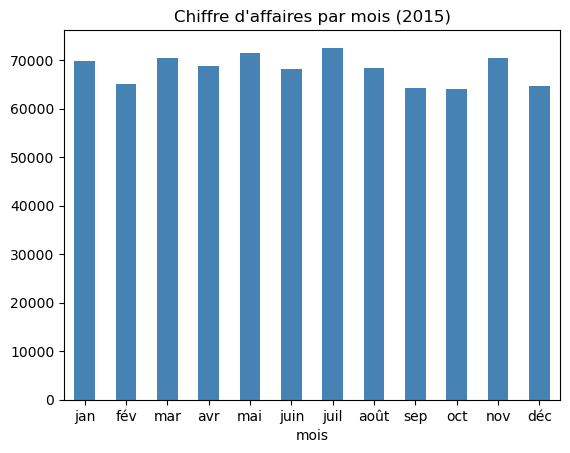

In [30]:
mois.plot(x="mois", y="chiffre_affaires", kind="bar", color="steelblue", legend=False, title="Chiffre d'affaires par mois (2015)")
plt.xticks(range(12), ["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"], rotation=0)   # noms des mois, à l'horizontale
plt.show()

### Observations
- Le chiffre d'affaires mensuel est assez stable : entre 64027.6 (octobre, le plus bas) et 72557.9 (juillet, le plus haut).
- Juillet est aussi le mois avec le plus de commandes (1935). Octobre en a le moins (1646), suivi de septembre (1661).
- Septembre et octobre sont les mois qui ont eu des jours sans commande (le 24 et le 25 septembre, et 4 lundis en octobre) : c'est probablement une partie de l'explication.
- Février reste à 65159.6 alors que c'est le mois le plus court.
- Limite : une seule année, donc on ne peut pas dire si c'est une vraie saisonnalité.

## 4. Ventes par jour de la semaine

In [17]:
requete = """
SELECT
    strftime('%w', orders.date) AS num_jour,
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires,
    COUNT(DISTINCT orders.order_id) AS nb_commandes,
    COUNT(DISTINCT orders.date) AS nb_jours,
    ROUND(COUNT(DISTINCT orders.order_id) * 1.0 / COUNT(DISTINCT orders.date), 1) AS commandes_par_jour
FROM order_details
JOIN orders ON order_details.order_id = orders.order_id
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
GROUP BY num_jour
ORDER BY num_jour
"""                              
jours = pd.read_sql(requete, con)   # garde le résultat dans la variable jours
jours

,num_jour,chiffre_affaires,nb_commandes,nb_jours,commandes_par_jour
0,0,99203.50,2624,52,50.5
1,1,107329.55,2794,48,58.2
2,2,114133.80,2973,52,57.2
3,3,114408.40,3024,52,58.2
4,4,123528.50,3239,52,62.3
5,5,136073.90,3538,50,70.8
6,6,123182.40,3158,52,60.7


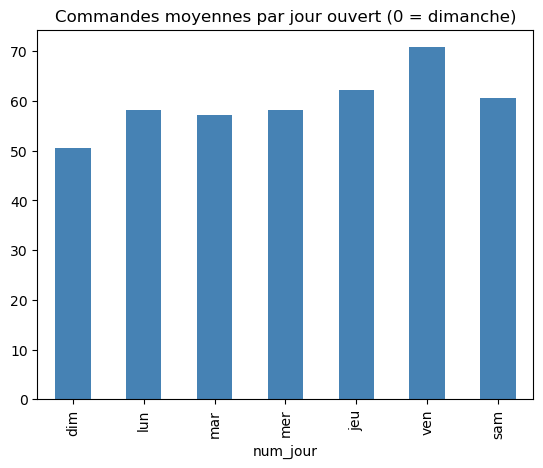

In [22]:
jours.plot(x="num_jour", y="commandes_par_jour", kind="bar", color="steelblue", legend=False, title="Commandes moyennes par jour ouvert (0 = dimanche)")
plt.xticks(range(7), ["dim", "lun", "mar", "mer", "jeu", "ven", "sam"])   # remplace 0...6 par le nom des jours
plt.show()

### Observations
- Les jours ne sont pas tous ouverts le même nombre de fois : 48 lundis et 50 vendredis, contre 52 pour les autres jours. On compare donc avec la moyenne de commandes par jour ouvert.
- Le vendredi est le jour le plus fort : 70.8 commandes par jour en moyenne et 136073.9 de CA sur l'année.
- Viennent ensuite le jeudi (62.3) et le samedi (60.7).
- Le dimanche est le jour le plus calme : 50.5 commandes par jour, et 99203.5 de CA.
- Le lundi, qui paraissait faible au total (2794 commandes), est en fait dans la moyenne avec 58.2 commandes par jour, autant que le mercredi.

## 5. Ventes par heure

In [18]:
requete = """
SELECT
    strftime('%H', orders.time) AS heure,
    COUNT(DISTINCT orders.order_id) AS nb_commandes,
    SUM(order_details.quantity) AS pizzas_vendues,
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires
FROM order_details
JOIN orders ON order_details.order_id = orders.order_id
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
GROUP BY heure
ORDER BY heure
"""                              # strftime('%H') garde seulement l'heure : 11:38:36 -> 11
heures = pd.read_sql(requete, con)   # garde le résultat dans la variable heures
heures

,heure,nb_commandes,pizzas_vendues,chiffre_affaires
0,09,1,4,83.00
1,10,8,18,303.65
2,11,1231,2728,44935.80
3,12,2520,6776,111877.90
4,13,2455,6413,106065.70
5,14,1472,3613,59201.40
6,15,1468,3216,52992.30
7,16,1920,4239,70055.40
8,17,2336,5211,86237.45
9,18,2399,5417,89296.85


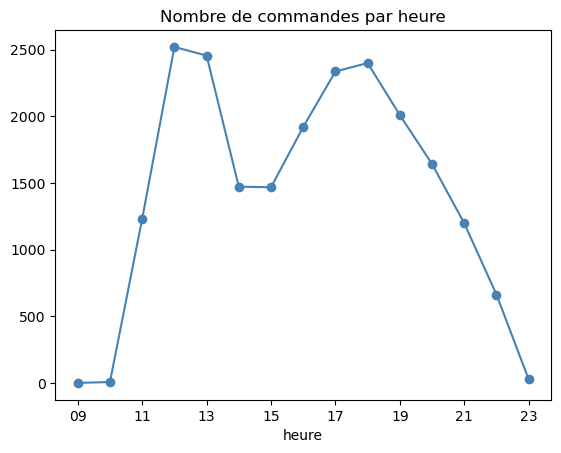

In [31]:
heures.plot(x="heure", y="nb_commandes", kind="line", marker="o", color="steelblue", legend=False, title="Nombre de commandes par heure")
plt.show()

### Observations
- Deux pics dans la journée :
  - le midi : 12h est l'heure la plus forte (2520 commandes, 6776 pizzas, 111877.90 de CA), suivie de 13h (2455 commandes) ;
  - le soir : 17h (2336 commandes) et 18h (2399 commandes).
- Creux de l'après-midi à 14h (1472 commandes) et 15h (1468).
- Avant 11h et à 23h, il n'y a presque rien : 1 commande à 9h, 8 à 10h, 28 à 23h.
- Utile pour la direction : renforcer l'équipe en cuisine entre 12h et 13h, puis entre 17h et 19h.

## 6. Meilleures et moins bonnes pizzas

In [11]:
requete = """
SELECT
    pizza_types.name AS pizza,
    pizza_types.category AS categorie,
    SUM(order_details.quantity) AS pizzas_vendues,
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires
FROM order_details
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
JOIN pizza_types ON pizzas.pizza_type_id = pizza_types.pizza_type_id
GROUP BY pizza_types.name
ORDER BY chiffre_affaires DESC
"""                              # un total par type de pizza (toutes tailles), du plus gros CA au plus petit
classement = pd.read_sql(requete, con)   # on garde le résultat dans une variable pour le réutiliser
classement

,pizza,categorie,pizzas_vendues,chiffre_affaires
0,The Thai Chicken Pizza,Chicken,2371,43434.25
1,The Barbecue Chicken Pizza,Chicken,2432,42768.00
2,The California Chicken Pizza,Chicken,2370,41409.50
3,The Classic Deluxe Pizza,Classic,2453,38180.50
4,The Spicy Italian Pizza,Supreme,1924,34831.25
5,The Southwest Chicken Pizza,Chicken,1917,34705.75
6,The Italian Supreme Pizza,Supreme,1884,33476.75
7,The Hawaiian Pizza,Classic,2422,32273.25
8,The Four Cheese Pizza,Veggie,1902,32265.70
9,The Sicilian Pizza,Supreme,1938,30940.50


In [12]:
print(classement.sort_values("pizzas_vendues", ascending=False).head(5))   # top 5 en nombre de pizzas vendues
print(classement.sort_values("pizzas_vendues").head(5))                    # les 5 qui se vendent le moins

                         pizza categorie  pizzas_vendues  chiffre_affaires
3     The Classic Deluxe Pizza   Classic            2453          38180.50
1   The Barbecue Chicken Pizza   Chicken            2432          42768.00
7           The Hawaiian Pizza   Classic            2422          32273.25
10         The Pepperoni Pizza   Classic            2418          30161.75
0       The Thai Chicken Pizza   Chicken            2371          43434.25
                        pizza categorie  pizzas_vendues  chiffre_affaires
31       The Brie Carre Pizza   Supreme             490          11588.50
28    The Mediterranean Pizza    Veggie             934          15360.50
26        The Calabrese Pizza   Supreme             937          15934.25
29  The Spinach Supreme Pizza   Supreme             950          15277.75
24      The Soppressata Pizza   Supreme             961          16425.75


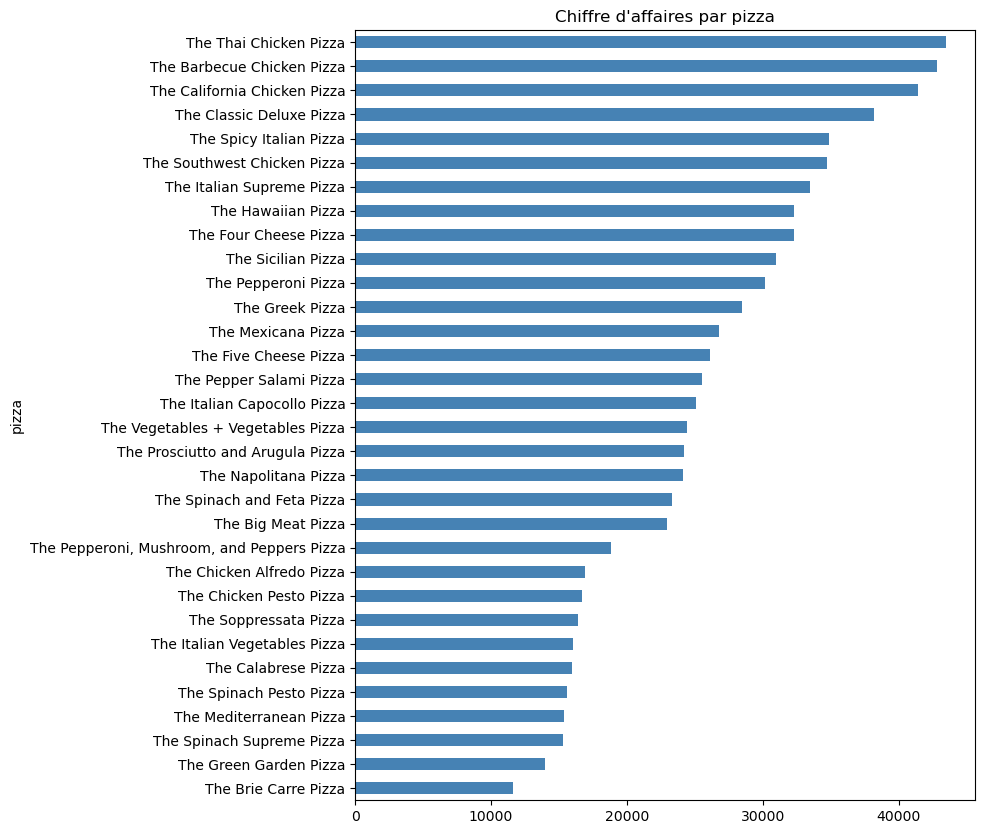

In [23]:
classement.plot(x="pizza", y="chiffre_affaires", kind="barh", color="steelblue", legend=False, figsize=(8, 10), title="Chiffre d'affaires par pizza")
plt.gca().invert_yaxis()   # met la meilleure pizza en haut
plt.show()

### Observations
- Les 3 pizzas qui rapportent le plus sont toutes des Chicken : The Thai Chicken Pizza (43434.25), The Barbecue Chicken Pizza (42768.00) et The California Chicken Pizza (41409.50).
- La pizza la plus vendue en quantité est The Classic Deluxe Pizza (2453), mais elle n'est que 4e en chiffre d'affaires (38180.50) : elle se vend beaucoup mais rapporte moins par pizza.
- Même chose pour The Hawaiian Pizza (2422 vendues, 8e en CA) et The Pepperoni Pizza (2418 vendues, 11e en CA).
- Les 10 dernières du classement ont toutes moins de 1000 pizzas vendues sur l'année.
- The Brie Carre Pizza est dernière en CA (11588.50) et en quantité (490). On a vu à l'exploration qu'elle n'existe qu'en taille S.
- Piste pour la direction : revoir la place des dernières pizzas sur la carte. Mais sans les coûts des ingrédients, on ne connaît pas leur marge : c'est une proposition à vérifier.

## 7. Catégories

In [13]:
requete = """
SELECT
    pizza_types.category AS categorie,
    COUNT(DISTINCT pizza_types.pizza_type_id) AS nb_types,
    SUM(order_details.quantity) AS pizzas_vendues,
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires
FROM order_details
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
JOIN pizza_types ON pizzas.pizza_type_id = pizza_types.pizza_type_id
GROUP BY categorie
ORDER BY chiffre_affaires DESC
"""                              # un total par catégorie ; nb_types = combien de pizzas différentes dans la catégorie
categories = pd.read_sql(requete, con)
categories["part_ca"] = (categories["chiffre_affaires"] / categories["chiffre_affaires"].sum() * 100).round(1)   # part du CA total en %
categories

,categorie,nb_types,pizzas_vendues,chiffre_affaires,part_ca
0,Classic,8,14888,220053.10,26.9
1,Supreme,9,11987,208197.00,25.5
2,Chicken,6,11050,195919.50,24.0
3,Veggie,9,11649,193690.45,23.7


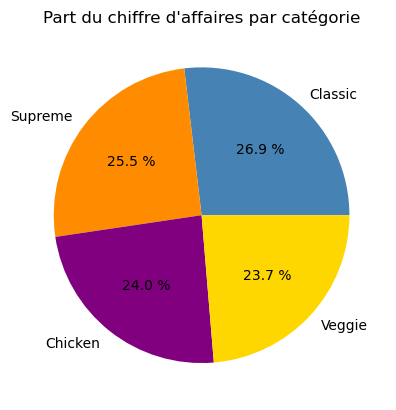

In [32]:
categories.plot(y="part_ca", kind="pie", labels=categories["categorie"],
                colors=["steelblue", "darkorange", "purple", "gold"],    # une couleur par catégorie, sans rouge ni vert
                autopct="%.1f %%", legend=False,                         # affiche le % sur chaque part
                title="Part du chiffre d'affaires par catégorie")
plt.ylabel("")   # enlève le texte "part_ca" sur le côté
plt.show()

### Observations
- Les 4 catégories se partagent le chiffre d'affaires de façon assez équilibrée : Classic 26.9 %, Supreme 25.5 %, Chicken 24.0 %, Veggie 23.7 %.
- Classic est la 1re catégorie en CA (220053.10) et en pizzas vendues (14888), avec 8 types.
- Chicken fait 24.0 % du CA avec seulement 6 types, contre 9 pour Supreme et Veggie : chaque pizza Chicken rapporte en moyenne plus que les autres. Ça confirme la partie 6, où les 3 meilleures pizzas en CA sont des Chicken.
- Veggie est dernière (193690.45) alors qu'elle a 9 types sur la carte.

## 8. Tailles

In [14]:
requete = """
SELECT
    pizzas.size AS taille,
    SUM(order_details.quantity) AS pizzas_vendues,
    ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires
FROM order_details
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
GROUP BY taille
ORDER BY chiffre_affaires DESC
"""                              # un total par taille : S, M, L, XL, XXL
tailles = pd.read_sql(requete, con)
tailles["part_ca"] = (tailles["chiffre_affaires"] / tailles["chiffre_affaires"].sum() * 100).round(1)   # part du CA en %
tailles

,taille,pizzas_vendues,chiffre_affaires,part_ca
0,L,18956,375318.70,45.9
1,M,15635,249382.25,30.5
2,S,14403,178076.50,21.8
3,XL,552,14076.00,1.7
4,XXL,28,1006.60,0.1


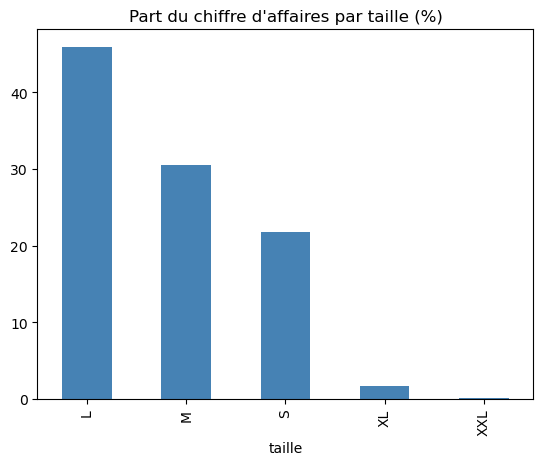

In [25]:
tailles.plot(x="taille", y="part_ca", kind="bar", color="steelblue", legend=False, title="Part du chiffre d'affaires par taille (%)")
plt.show()

### Observations
- La taille L domine : 45.9 % du CA (375318.70) et 18956 pizzas vendues.
- Viennent ensuite M (30.5 %) et S (21.8 %).
- Les grandes tailles de la the_greek pèsent très peu : XL 1.7 % (552 pizzas) et XXL 0.1 % (28 pizzas sur toute l'année).
- Piste pour la direction : la XXL se vend très peu, on pourrait la retirer de la carte. C'est une proposition à vérifier avec la direction.

## 9. Pizzas par commande

In [26]:
requete = """
SELECT
    nb_pizzas,
    COUNT(*) AS nb_commandes
FROM (
    SELECT order_details.order_id, SUM(order_details.quantity) AS nb_pizzas
    FROM order_details
    GROUP BY order_details.order_id
) AS commandes
GROUP BY nb_pizzas
ORDER BY nb_pizzas
"""
taille_commandes = pd.read_sql(requete, con)
taille_commandes["part"] = (taille_commandes["nb_commandes"] / taille_commandes["nb_commandes"].sum() * 100).round(1)   # % des commandes
taille_commandes

,nb_pizzas,nb_commandes,part
0,1,8111,38.0
1,2,6152,28.8
2,3,3207,15.0
3,4,3122,14.6
4,5,145,0.7
5,6,80,0.4
6,7,61,0.3
7,8,67,0.3
8,9,64,0.3
9,10,56,0.3


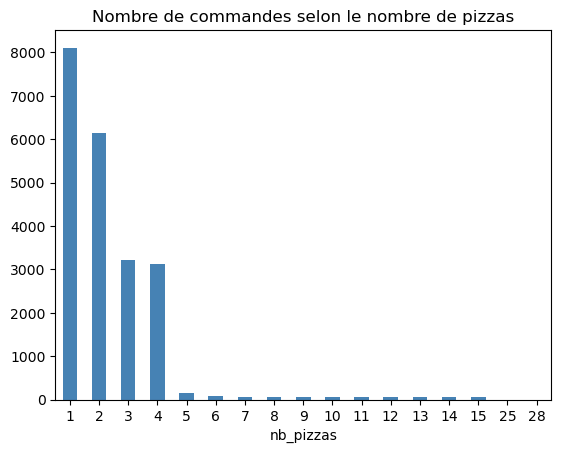

In [33]:
taille_commandes.plot(x="nb_pizzas", y="nb_commandes", kind="bar", color="steelblue", legend=False, title="Nombre de commandes selon le nombre de pizzas")
plt.xticks(rotation=0)   # chiffres à l'horizontale
plt.show()

### Observations
- La commande la plus fréquente est d'une seule pizza : 8111 commandes, soit 38.0 %.
- Viennent ensuite les commandes de 2 pizzas (6152, 28.8 %), de 3 pizzas (3207, 15.0 %) et de 4 pizzas (3122, 14.6 %).
- À partir de 5 pizzas, chaque taille de commande représente 0.7 % des commandes ou moins.
- Il existe quelques très grosses commandes : une de 25 pizzas et une de 28 pizzas (on les regardera dans la partie 12).
- Piste pour la direction : les commandes de 2 à 4 pizzas sont fréquentes, une offre « duo » ou « famille » pourrait faire grossir le panier. C'est à tester.

## 10. Jour et heure croisés

In [34]:
requete = """
SELECT
    strftime('%w', orders.date) AS num_jour,
    strftime('%H', orders.time) AS heure,
    COUNT(orders.order_id) AS nb_commandes
FROM orders
GROUP BY num_jour, heure
"""                              # un total pour chaque couple (jour, heure) ; ici la table orders suffit
jour_heure = pd.read_sql(requete, con)
tableau = jour_heure.pivot(index="num_jour", columns="heure", values="nb_commandes").fillna(0)   # jours en lignes, heures en colonnes
tableau

heure,09,10,11,12,13,14,15,16,17,18,19,20,21,22,23
num_jour,,,,,,,,,,,,,,,
0,0.0,1.0,95.0,210.0,261.0,214.0,222.0,278.0,322.0,324.0,281.0,197.0,147.0,70.0,2.0
1,0.0,1.0,226.0,398.0,331.0,182.0,192.0,247.0,317.0,303.0,235.0,174.0,134.0,53.0,1.0
2,1.0,0.0,188.0,421.0,371.0,196.0,191.0,295.0,309.0,301.0,274.0,214.0,131.0,81.0,0.0
3,0.0,2.0,231.0,420.0,381.0,201.0,210.0,259.0,343.0,335.0,238.0,193.0,139.0,72.0,0.0
4,0.0,3.0,214.0,434.0,438.0,233.0,228.0,289.0,376.0,361.0,270.0,217.0,114.0,60.0,2.0
5,0.0,0.0,192.0,415.0,413.0,221.0,190.0,258.0,344.0,387.0,340.0,319.0,268.0,180.0,11.0
6,0.0,1.0,85.0,222.0,260.0,225.0,235.0,294.0,325.0,388.0,371.0,328.0,265.0,147.0,12.0


In [35]:
print(jour_heure.sort_values("nb_commandes", ascending=False).head(5))   # les 5 créneaux (jour, heure) les plus chargés

   num_jour heure  nb_commandes
57        4    13           438
56        4    12           434
30        2    12           421
43        3    12           420
69        5    12           415


### Observations
- Le midi est surtout un pic de semaine : de lundi à vendredi, 12h et 13h dépassent 330 commandes (jusqu'à 438 le jeudi à 13h), alors que le samedi et le dimanche restent entre 210 et 261.
- Le soir est fort tous les jours, et encore plus en fin de semaine : 387 commandes le vendredi à 18h et 388 le samedi à 18h.
- Le vendredi et le samedi, l'activité dure plus tard : 180 commandes le vendredi à 22h et 147 le samedi, contre 81 au plus les autres jours.
- Hypothèse à vérifier : une clientèle de bureau en semaine le midi, et des repas en famille ou entre amis le soir et le week-end.
- Limite : ce sont des totaux sur l'année. Les lundis et les vendredis ont eu moins de jours ouverts (48 et 50), donc leurs cases sont un peu sous-estimées.
- Piste pour le planning : renforcer l'équipe le midi en semaine, et le soir surtout le vendredi et le samedi, jusqu'à 23h.

## 11. Meilleurs et pires jours

In [36]:
requete = """
SELECT orders.date AS date,
       ROUND(SUM(order_details.quantity * pizzas.price), 2) AS chiffre_affaires,
       COUNT(DISTINCT orders.order_id) AS nb_commandes
FROM orders
JOIN order_details ON orders.order_id = order_details.order_id
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
GROUP BY orders.date
ORDER BY orders.date
"""
ca_jour = pd.read_sql(requete, con)   # une ligne par jour ouvert
ca_jour["date"] = pd.to_datetime(ca_jour["date"])   # transforme le texte en vraie date pour le graphique
ca_jour

,date,chiffre_affaires,nb_commandes
0,2015-01-01,2713.85,69
1,2015-01-02,2731.90,67
2,2015-01-03,2662.40,66
3,2015-01-04,1755.45,52
4,2015-01-05,2065.95,54
...,...,...,...
353,2015-12-27,1419.00,35
354,2015-12-28,1637.20,39
355,2015-12-29,1353.25,27
356,2015-12-30,1337.80,32


In [39]:
print(ca_jour.sort_values("chiffre_affaires", ascending=False).head(5))   # les 5 meilleurs jours
print(ca_jour.sort_values("chiffre_affaires").head(5))                    # les 5 pires jours
print(ca_jour["chiffre_affaires"].mean())                                 # CA moyen par jour
ca_jour["jour"] = ca_jour["date"].dt.day_name()   # ajoute le nom du jour (Monday, Tuesday...)
print(ca_jour.sort_values("chiffre_affaires", ascending=False).head(5))
print(ca_jour.sort_values("chiffre_affaires").head(5))
print(round(ca_jour["chiffre_affaires"].mean(), 2))   # moyenne arrondie à 2 décimales

          date  chiffre_affaires  nb_commandes
324 2015-11-27           4422.45           115
323 2015-11-26           4405.95           113
283 2015-10-15           4320.20           107
184 2015-07-04           3864.20           105
183 2015-07-03           3443.00            93
          date  chiffre_affaires  nb_commandes
80  2015-03-22           1259.25            37
356 2015-12-30           1337.80            32
355 2015-12-29           1353.25            27
319 2015-11-22           1368.70            43
353 2015-12-27           1419.00            35
2284.5252793296086
          date  chiffre_affaires  nb_commandes      jour
324 2015-11-27           4422.45           115    Friday
323 2015-11-26           4405.95           113  Thursday
283 2015-10-15           4320.20           107  Thursday
184 2015-07-04           3864.20           105  Saturday
183 2015-07-03           3443.00            93    Friday
          date  chiffre_affaires  nb_commandes       jour
80  2015-03-22   

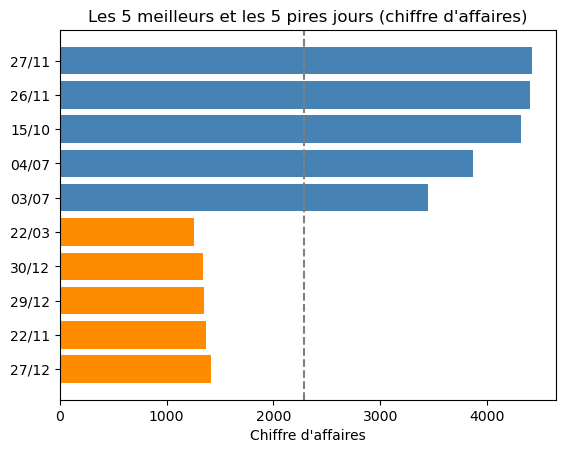

In [40]:
extremes = pd.concat([ca_jour.sort_values("chiffre_affaires", ascending=False).head(5),
                      ca_jour.sort_values("chiffre_affaires").head(5)])   # colle les 5 meilleurs et les 5 pires
couleurs = ["steelblue"] * 5 + ["darkorange"] * 5                          # bleu pour les meilleurs, orange pour les pires

plt.barh(extremes["date"].dt.strftime("%d/%m"), extremes["chiffre_affaires"], color=couleurs)
plt.axvline(ca_jour["chiffre_affaires"].mean(), color="grey", linestyle="--")   # ligne du CA moyen
plt.gca().invert_yaxis()   # le meilleur jour en haut
plt.title("Les 5 meilleurs et les 5 pires jours (chiffre d'affaires)")
plt.xlabel("Chiffre d'affaires")
plt.show()

### Observations

- En moyenne, la pizzeria fait 2284.53 de chiffre d'affaires par jour.
- Les meilleurs jours sont très au-dessus de cette moyenne : 4422.45 le vendredi 27/11 (115 commandes), 4405.95 le jeudi 26/11 (113), 4320.20 le jeudi 15/10 (107), puis 3864.20 le samedi 04/07 (105) et 3443.00 le vendredi 03/07 (93).
- Hypothèse à vérifier : si le restaurant est aux États-Unis, le 26/11 correspond à Thanksgiving, le 27/11 au Black Friday, et le début juillet à la fête nationale du 4 juillet. Rien dans les données n'explique le pic du 15/10.
- Le pire jour est le dimanche 22/03 (1259.25, 37 commandes). Viennent ensuite le mercredi 30/12 (1337.80), le mardi 29/12 (1353.25), le dimanche 22/11 (1368.70) et le dimanche 27/12 (1419.00).
- Trois des cinq pires jours tombent entre Noël et le Nouvel An, probablement à cause des fêtes. Trois sont aussi des dimanches, le jour le plus faible de la semaine (partie 4).
- Piste : prévoir plus de stock et de personnel pour les jours de fête, et une équipe réduite entre Noël et le Nouvel An.

## 12. Très grosses commandes

In [41]:
requete = """
SELECT orders.order_id,
       orders.date,
       orders.time,
       SUM(order_details.quantity) AS nb_pizzas,
       ROUND(SUM(order_details.quantity * pizzas.price), 2) AS montant
FROM orders
JOIN order_details ON orders.order_id = order_details.order_id
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
GROUP BY orders.order_id
"""
commandes = pd.read_sql(requete, con)   # une ligne par commande, avec son nombre de pizzas et son montant
commandes

,order_id,date,time,nb_pizzas,montant
0,1,2015-01-01,11:38:36,1,13.25
1,2,2015-01-01,11:57:40,5,92.00
2,3,2015-01-01,12:12:28,2,37.25
3,4,2015-01-01,12:16:31,1,16.50
4,5,2015-01-01,12:21:30,1,16.50
...,...,...,...,...,...
21345,21346,2015-12-31,20:51:07,4,62.25
21346,21347,2015-12-31,21:14:37,4,66.50
21347,21348,2015-12-31,21:23:10,3,46.70
21348,21349,2015-12-31,22:09:54,1,20.25


In [42]:
grosses = commandes[commandes["nb_pizzas"] >= 10]   # garde les commandes de 10 pizzas ou plus
print(len(grosses))                                                                  # combien il y en a
print(round(grosses["montant"].sum() / commandes["montant"].sum() * 100, 1))         # leur part du CA en %
print(grosses.sort_values("montant", ascending=False).head(5))                       # les 5 plus grosses

341
8.7
       order_id        date      time  nb_pizzas  montant
18844     18845  2015-11-18  12:25:12         28   444.20
10759     10760  2015-06-30  13:31:27         25   417.15
1095       1096  2015-01-19  12:56:45         15   285.15
6168       6169  2015-04-14  13:14:51         15   284.00
739         740  2015-01-13  12:29:51         15   280.95


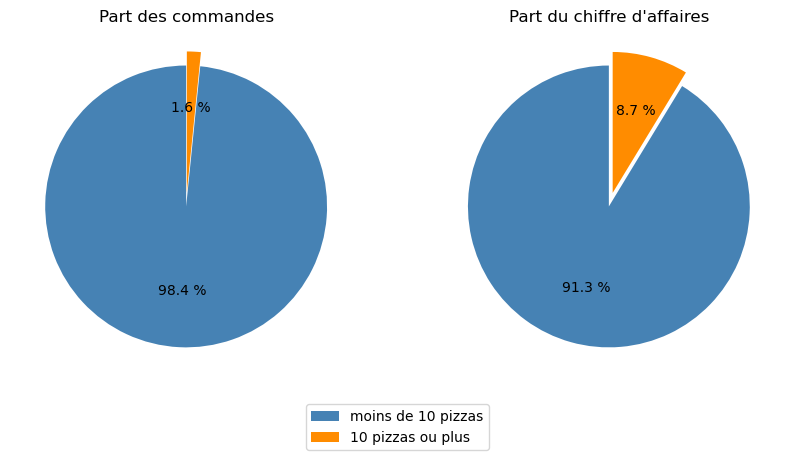

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))   # une figure avec 2 camemberts côte à côte

axes[0].pie(part["commandes"], colors=["steelblue", "darkorange"], autopct="%.1f %%", explode=[0, 0.1], startangle=90)
axes[0].set_title("Part des commandes")

axes[1].pie(part["chiffre_affaires"], colors=["steelblue", "darkorange"], autopct="%.1f %%", explode=[0, 0.1], startangle=90)
axes[1].set_title("Part du chiffre d'affaires")

fig.legend(part.index, loc="lower center")   # une seule légende pour les deux
plt.show()

### Observations

- 341 commandes contiennent 10 pizzas ou plus, contre 21009 pour les autres.
- Elles ne pèsent que 1.6 % des commandes, mais 8.7 % du chiffre d'affaires (71136.25 sur l'année).
- Les 5 plus grosses : 28 pizzas pour 444.20 le 18/11, 25 pizzas pour 417.15 le 30/06, puis trois commandes de 15 pizzas entre 280.95 et 285.15.
- Ces 5 commandes ont toutes été passées le midi, entre 12:25 et 13:31.
- Hypothèse à vérifier : ce sont probablement des commandes de groupe (bureaux, réunions) au moment du déjeuner.
- Piste : proposer une offre « groupe » ou une précommande la veille, pour mieux préparer ces commandes au moment du pic de midi.

## 13. Pizzas par heure au pic

In [49]:
requete = """
SELECT orders.date,
       strftime('%H', orders.time) AS heure,
       SUM(order_details.quantity) AS nb_pizzas
FROM orders
JOIN order_details ON orders.order_id = order_details.order_id
GROUP BY orders.date, heure
"""
pizzas_heure = pd.read_sql(requete, con)   # une ligne = un jour + une heure, avec le nombre de pizzas
pizzas_heure

,date,heure,nb_pizzas
0,2015-01-01,11,6
1,2015-01-01,12,17
2,2015-01-01,13,33
3,2015-01-01,14,15
4,2015-01-01,15,14
...,...,...,...
4176,2015-12-31,19,23
4177,2015-12-31,20,17
4178,2015-12-31,21,7
4179,2015-12-31,22,1


In [50]:
print(pizzas_heure.groupby("heure")["nb_pizzas"].describe())   # pour chaque heure : nombre, moyenne, min, quartiles, max

       count       mean        std  min    25%   50%    75%   max
heure                                                            
09       1.0   4.000000        NaN  4.0   4.00   4.0   4.00   4.0
10       8.0   2.250000   0.886405  1.0   1.75   2.5   3.00   3.0
11     331.0   8.241692   5.607534  1.0   4.00   7.0  11.00  28.0
12     357.0  18.980392  10.306110  2.0  11.00  18.0  25.00  49.0
13     358.0  17.913408   9.682106  1.0  11.00  17.0  24.00  64.0
14     349.0  10.352436   6.430363  1.0   5.00   9.0  14.00  33.0
15     355.0   9.059155   5.100060  1.0   5.00   8.0  12.00  27.0
16     356.0  11.907303   5.542141  1.0   8.00  11.0  15.00  32.0
17     357.0  14.596639   6.487654  1.0  10.00  14.0  18.00  41.0
18     357.0  15.173669   6.350978  1.0  11.00  14.0  19.00  39.0
19     357.0  12.341737   6.369323  1.0   8.00  12.0  16.00  42.0
20     352.0  10.039773   5.753097  1.0   6.00   9.0  13.25  35.0
21     341.0   7.463343   5.242022  1.0   4.00   6.0  10.00  34.0
22     276

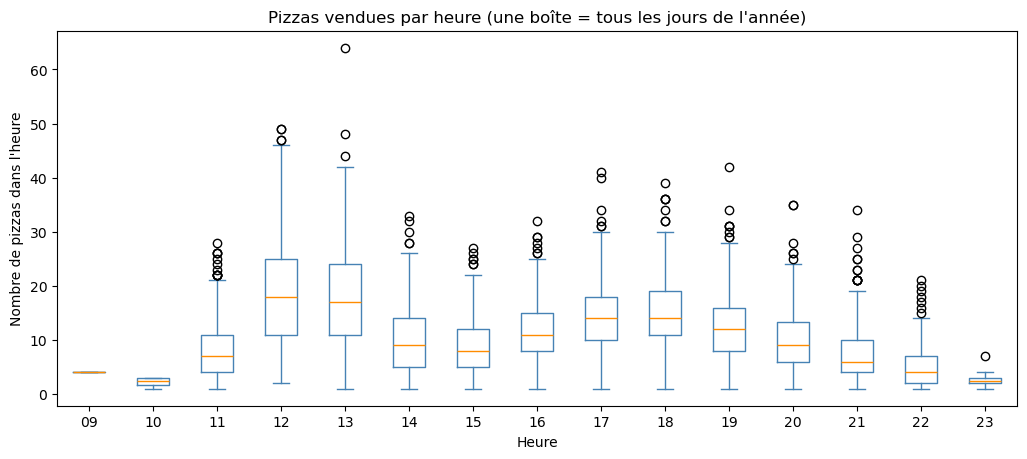

In [53]:
pizzas_heure.boxplot(column="nb_pizzas", by="heure", grid=False, figsize=(12, 5),
                     boxprops=dict(color="steelblue"),        # couleur des boîtes
                     whiskerprops=dict(color="steelblue"),    # couleur des moustaches
                     capprops=dict(color="steelblue"),        # couleur des petits traits au bout
                     medianprops=dict(color="darkorange"))    # couleur de la médiane
plt.suptitle("")   # enlève le titre automatique ajouté par pandas
plt.title("Pizzas vendues par heure (une boîte = tous les jours de l'année)")
plt.xlabel("Heure")
plt.ylabel("Nombre de pizzas dans l'heure")
plt.show()

In [54]:
print(pizzas_heure.sort_values("nb_pizzas", ascending=False).head(5))   # les 5 heures les plus chargées de l'année

            date heure  nb_pizzas
3309  2015-10-15    13         64
84    2015-01-08    12         49
1795  2015-06-04    12         49
2452  2015-07-30    13         48
384   2015-02-03    12         47


### Observations

- Le midi est le moment le plus chargé : à 12h, la médiane est de 18 pizzas dans l'heure, et à 13h de 17. Un jour sur quatre, on dépasse 25 pizzas à 12h et 24 à 13h.
- Le soir est moins intense mais régulier : la médiane est de 14 pizzas à 17h et à 18h.
- Entre les deux, l'activité baisse : médiane de 9 pizzas à 14h et de 8 à 15h.
- Les ronds sont des heures exceptionnelles, pas des erreurs. Le record est de 64 pizzas le 15/10 à 13h, puis 49 le 08/01 et le 04/06 à 12h.
- Le 15/10 était déjà le 3e meilleur jour de l'année (partie 11) : ce jour-là, c'est l'heure de 13h qui a fait la différence, probablement à cause d'une très grosse commande (à vérifier).
- Piste : prévoir la cuisine pour 25 pizzas par heure à midi (le 3e quartile de 12h), ce qui couvre trois jours sur quatre, et garder une marge pour les heures exceptionnelles.

## 14. Ingrédients les plus utilisés

In [55]:
requete = """
SELECT pizza_types.ingredients,
       SUM(order_details.quantity) AS pizzas_vendues
FROM order_details
JOIN pizzas ON order_details.pizza_id = pizzas.pizza_id
JOIN pizza_types ON pizzas.pizza_type_id = pizza_types.pizza_type_id
GROUP BY pizza_types.ingredients
"""
ingredients = pd.read_sql(requete, con)   # une ligne par recette, avec le nombre de pizzas vendues
ingredients

,ingredients,pizzas_vendues
0,"Bacon, Pepperoni, Italian Sausage, Chorizo Sau...",1914
1,"Barbecued Chicken, Red Peppers, Green Peppers,...",2432
2,"Brie Carre Cheese, Prosciutto, Caramelized Oni...",490
3,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",1884
4,"Capocollo, Red Peppers, Tomatoes, Goat Cheese,...",1438
5,"Capocollo, Tomatoes, Goat Cheese, Artichokes, ...",1924
6,"Chicken, Artichoke, Spinach, Garlic, Jalapeno ...",2370
7,"Chicken, Pineapple, Tomatoes, Red Peppers, Tha...",2371
8,"Chicken, Red Onions, Red Peppers, Mushrooms, A...",987
9,"Chicken, Tomatoes, Red Peppers, Red Onions, Ja...",1917


In [56]:
ingredients["ingredient"] = ingredients["ingredients"].str.split(", ")   # transforme le texte en liste d'ingrédients
ingredients = ingredients.explode("ingredient")                          # une ligne par ingrédient
top_ingredients = ingredients.groupby("ingredient")["pizzas_vendues"].sum().sort_values(ascending=False)
print(len(top_ingredients))     # nombre d'ingrédients différents
print(top_ingredients.head(10)) # les 10 plus utilisés

65
ingredient
Garlic               27913
Tomatoes             27052
Red Onions           19834
Red Peppers          16562
Mozzarella Cheese    10569
Pepperoni            10540
Spinach              10166
Mushrooms             9729
Chicken               8618
Capocollo             6692
Name: pizzas_vendues, dtype: int64


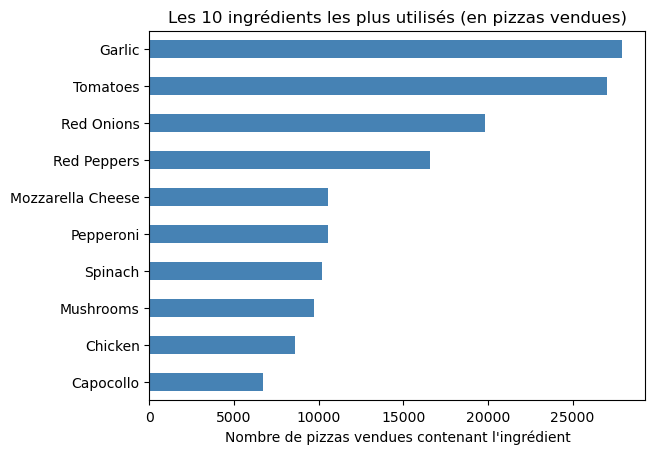

In [57]:
top_ingredients.head(10).plot(kind="barh", color="steelblue")
plt.gca().invert_yaxis()   # le plus utilisé en haut
plt.title("Les 10 ingrédients les plus utilisés (en pizzas vendues)")
plt.xlabel("Nombre de pizzas vendues contenant l'ingrédient")
plt.ylabel("")
plt.show()

### Observations

- Les 32 recettes utilisent 65 ingrédients différents.
- L'ail (Garlic) est l'ingrédient le plus utilisé : il est présent dans 27913 pizzas vendues sur les 49574 de l'année (partie 2). Les tomates suivent de près, avec 27052.
- Viennent ensuite les oignons rouges (19834) et les poivrons rouges (16562).
- Mozzarella Cheese, Pepperoni et Spinach sont presque à égalité (10569, 10540 et 10166).
- Limite : la colonne ingredients semble lister surtout les garnitures. La mozzarella n'arrive que 5e alors que la plupart des pizzas en contiennent, et la sauce n'apparaît pas. À vérifier dans la description des données.
- Limite : on compte des pizzas, pas des quantités (grammes). On sait quels ingrédients sont souvent utilisés, mais pas combien en acheter.
- Piste : sécuriser en priorité l'approvisionnement en ail, tomates, oignons rouges et poivrons rouges, qui sont dans le plus grand nombre de pizzas vendues.

## 15. Conclusion

### Ce qu'il faut retenir
- En 2015, Plato's Pizza a fait 817860.05 de chiffre d'affaires, avec 21350 commandes et 49574 pizzas vendues. Le panier moyen est de 38.31 (partie 2).
- Les ventes sont stables sur l'année : de 64027.6 en octobre à 72557.9 en juillet (partie 3).
- Le vendredi est le jour le plus fort (70.8 commandes par jour ouvert) et le dimanche le plus faible (50.5) (partie 4).
- Deux pics par jour : le midi (12h et 13h, surtout en semaine) et le début de soirée (17h et 18h) (parties 5, 10 et 13).
- Le top du chiffre d'affaires est occupé par les pizzas au poulet (Thai Chicken 43434.25). La plus vendue en nombre est la Classic Deluxe (2453). La Brie Carre est dernière sur les deux classements (partie 6).
- Les 4 catégories pèsent presque autant (de 23.7 % à 26.9 % du CA). La taille L domine (45.9 %), et XL et XXL ne pèsent presque rien (partie 7 et 8).
- 38.0 % des commandes ne contiennent qu'une pizza (partie 9). Les commandes de 10 pizzas ou plus ne font que 1.6 % des commandes, mais 8.7 % du CA (partie 12).

### Recommandations 
- Renforcer l'équipe le midi en semaine et le soir le vendredi et le samedi, en prévoyant 25 pizzas par heure à midi (partie 13).
- Pousser le passage de 1 à 2 pizzas par commande (offre duo, menu) pour augmenter le panier moyen.
- Proposer une offre « groupe » ou une précommande pour les grosses commandes du midi.
- Réfléchir à l'avenir de la Brie Carre et des tailles XL et XXL, qui se vendent peu.
- Anticiper les jours de fête (fin novembre, début juillet) et réduire l'équipe entre Noël et le Nouvel An.

### Limites
- Une seule année de données (2015) : impossible de vérifier si les tendances se répètent.
- Pas de coûts, donc pas de marge : une pizza qui rapporte beaucoup n'est pas forcément rentable.
- Pas d'identifiant client, ni de canal de vente (sur place, à emporter, livraison).
- La monnaie n'est pas précisée dans les données.
- 7 jours sans commande (fermetures probables) et moins de lundis et de vendredis ouverts.
- La colonne ingredients ne liste probablement que les garnitures, sans les quantités.

In [58]:
con.close()   # ferme la connexion à la base